<a href="https://colab.research.google.com/github/Haidermushtaq/Computer-Vision-/blob/main/FA23_BAI_044_HaiderMushtaq_LabMid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Haider Mushtaq  
**Reg No:** FA23-BAI-044

## My Personal Settings
Last two digits of reg no 044 = **44**, last digit = **4**

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits | 44 |
| HOG cell size | 4 is even | 8 x 8 |
| SIFT grid size | 4 is in 0 to 4 | 4 x 4 grid (16 keypoints) |

In [6]:
# My personal settings (reg no 044)
SEED = 44
HOG_CELL = 8      # 8 x 8 pixels per cell
GRID = 4          # 4 x 4 grid = 16 SIFT keypoints

In [7]:
!pip install -q medmnist opencv-python-headless scikit-image scikit-learn

In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

CLASSES = [1, 5, 6, 7]
NAMES = {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}
rng = np.random.default_rng(SEED)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


## Q1. Data setup

In [8]:
def load_split(split, n_per_class):
    data = BloodMNIST(split=split, download=True, size=64)
    imgs = data.imgs              # (N, 64, 64, 3)
    labels = data.labels.ravel()  # (N,)

    X, y = [], []
    for c in CLASSES:
        idx = np.where(labels == c)[0]
        pick = rng.choice(idx, n_per_class, replace=False)   # random pick using my seed
        for i in pick:
            gray = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)  # colour to grayscale
            gray = cv2.resize(gray, (128, 128))               # 64x64 to 128x128
            X.append(gray)
            y.append(c)
    return np.array(X), np.array(y)

X_train, y_train = load_split('train', 100)
X_val,   y_val   = load_split('val',   30)
X_test,  y_test  = load_split('test',  30)

for name, X, y in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    counts = {NAMES[c]: int((y == c).sum()) for c in CLASSES}
    print(name, X.shape, counts)

100%|██████████| 156M/156M [00:57<00:00, 2.70MB/s]


Train (400, 128, 128) {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
Val (120, 128, 128) {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
Test (120, 128, 128) {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


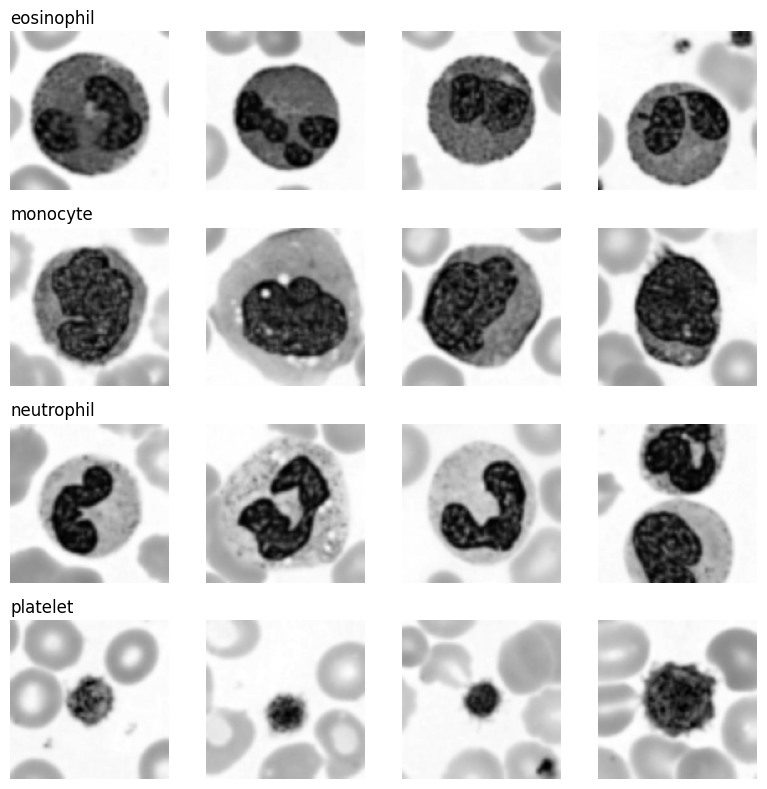

In [9]:
# 4 example images per class (one row per class)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, c in enumerate(CLASSES):
    idx = np.where(y_train == c)[0][:4]
    for k, i in enumerate(idx):
        axes[r, k].imshow(X_train[i], cmap='gray')
        axes[r, k].axis('off')
    axes[r, 0].set_title(NAMES[c], loc='left')
plt.tight_layout()
plt.show()

## Q2. HOG + SVM

In [10]:
def hog_features(images):
    feats = []
    for img in images:
        f = hog(img, orientations=9,
                pixels_per_cell=(HOG_CELL, HOG_CELL),
                cells_per_block=(2, 2))
        feats.append(f)
    return np.array(feats)

H_train = hog_features(X_train)
H_val   = hog_features(X_val)
print('HOG feature length:', H_train.shape[1])

HOG feature length: 8100


**HOG length by hand (cell 8 x 8):**
- Cells per side = 128 / 8 = 16
- Blocks per side (block = 2 x 2 cells, moves 1 cell at a time) = 16 - 2 + 1 = 15
- Total blocks = 15 x 15 = 225
- Values per block = 2 x 2 cells x 9 orientations = 36
- Feature length = 225 x 36 = **8100**

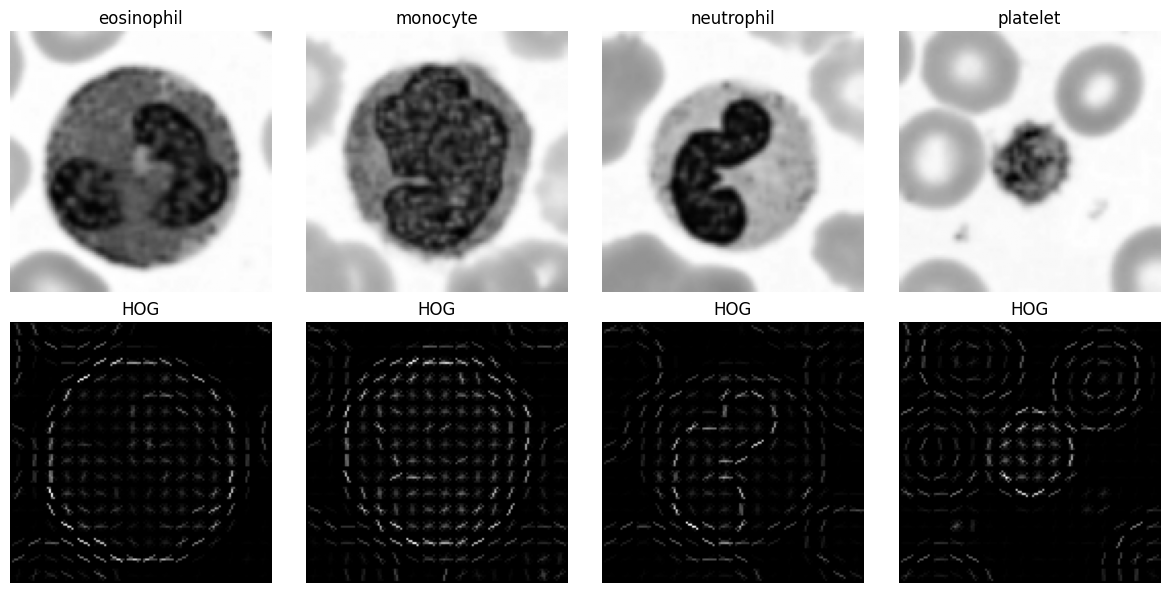

In [11]:
# HOG picture for one image from each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k, c in enumerate(CLASSES):
    img = X_train[np.where(y_train == c)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), visualize=True)
    axes[0, k].imshow(img, cmap='gray');     axes[0, k].set_title(NAMES[c])
    axes[1, k].imshow(hog_img, cmap='gray'); axes[1, k].set_title('HOG')
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.tight_layout()
plt.show()

C = 0.1: validation accuracy = 0.733
C = 1: validation accuracy = 0.733
C = 10: validation accuracy = 0.733

Best C = 0.1
Validation accuracy = 0.733
Validation macro-F1 = 0.734


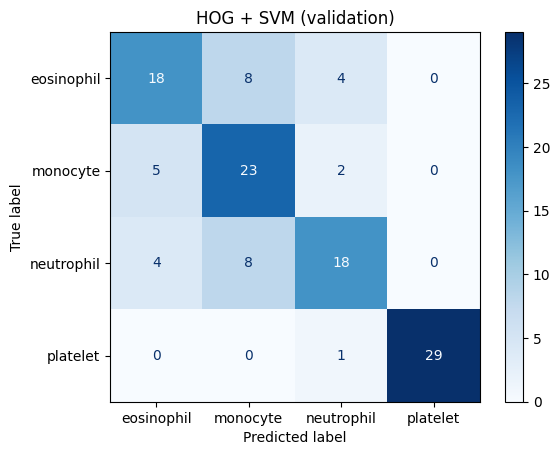

In [12]:
def train_svm(F_train, y_train, F_val, y_val, title):
    best_acc, best_C, best_model = -1, None, None
    for C in [0.1, 1, 10]:
        model = make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=10000, random_state=SEED))
        model.fit(F_train, y_train)
        acc = accuracy_score(y_val, model.predict(F_val))
        print(f'C = {C}: validation accuracy = {acc:.3f}')
        if acc > best_acc:
            best_acc, best_C, best_model = acc, C, model

    pred = best_model.predict(F_val)
    print(f'\nBest C = {best_C}')
    print(f'Validation accuracy = {accuracy_score(y_val, pred):.3f}')
    print(f'Validation macro-F1 = {f1_score(y_val, pred, average="macro"):.3f}')

    cm = confusion_matrix(y_val, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=[NAMES[c] for c in CLASSES]).plot(cmap='Blues')
    plt.title(title + ' (validation)')
    plt.show()
    return best_model

hog_model = train_svm(H_train, y_train, H_val, y_val, 'HOG + SVM')

## Q3. SIFT + SVM

Average keypoints per image: 70.67
Minimum keypoints: 10
Maximum keypoints: 240
Images with zero keypoints: 0


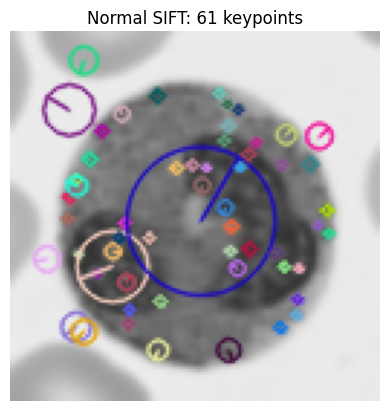

In [13]:
sift = cv2.SIFT_create()

# Normal SIFT detection on training images
counts = []
for img in X_train:
    kp, des = sift.detectAndCompute(img, None)
    counts.append(len(kp))
counts = np.array(counts)

print('Average keypoints per image:', round(counts.mean(), 2))
print('Minimum keypoints:', counts.min())
print('Maximum keypoints:', counts.max())
print('Images with zero keypoints:', (counts == 0).sum())

# Draw keypoints on one image
kp, _ = sift.detectAndCompute(X_train[0], None)
drawn = cv2.drawKeypoints(X_train[0], kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(drawn); plt.title(f'Normal SIFT: {len(kp)} keypoints'); plt.axis('off'); plt.show()

**Why is this a problem for SVM?** An SVM needs every image to give a feature vector of the same length, but with normal SIFT each image gives a different number of keypoints (some give zero), so the descriptors cannot be stacked into one fixed size vector.

Grid points: 16
SIFT feature length: 2048


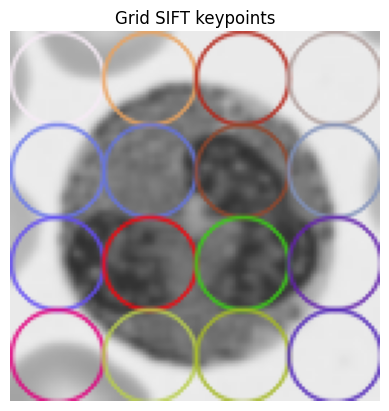

In [14]:
# Fixed grid of keypoints: 4 x 4 grid over 128 x 128 image
step = 128 // GRID                              # 32 pixels between points
centers = [step // 2 + i * step for i in range(GRID)]   # 16, 48, 80, 112
grid_kp = [cv2.KeyPoint(float(x), float(y), 32) for y in centers for x in centers]

def sift_features(images):
    feats = []
    for img in images:
        _, des = sift.compute(img, grid_kp)   # des shape = (16, 128)
        feats.append(des.flatten())           # join into one vector
    return np.array(feats)

S_train = sift_features(X_train)
S_val   = sift_features(X_val)
print('Grid points:', len(grid_kp))
print('SIFT feature length:', S_train.shape[1])

drawn = cv2.drawKeypoints(X_train[0], grid_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(drawn); plt.title('Grid SIFT keypoints'); plt.axis('off'); plt.show()

**SIFT length by hand (4 x 4 grid):**
- Grid points = 4 x 4 = 16
- Each SIFT descriptor = 4 x 4 sub-regions x 8 orientation bins = 128
- Feature length = 16 x 128 = **2048**

C = 0.1: validation accuracy = 0.758
C = 1: validation accuracy = 0.767
C = 10: validation accuracy = 0.767

Best C = 1
Validation accuracy = 0.767
Validation macro-F1 = 0.762


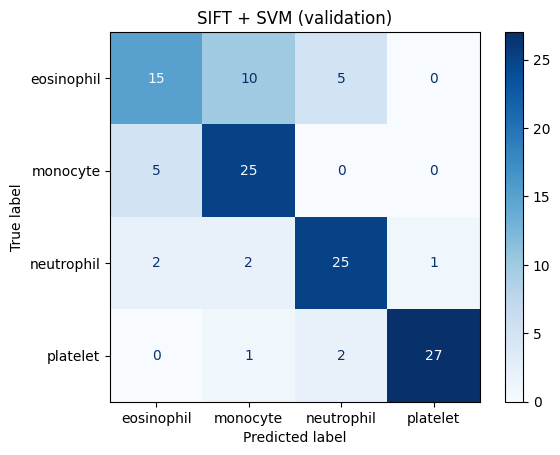

In [15]:
sift_model = train_svm(S_train, y_train, S_val, y_val, 'SIFT + SVM')

## Q4. Robustness

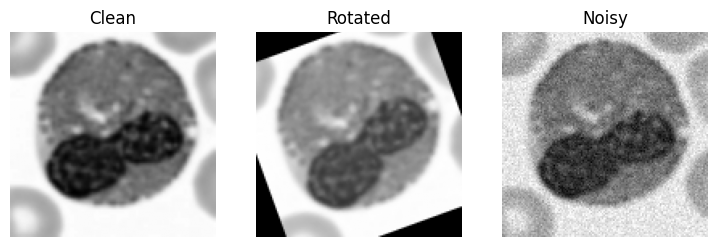

In [16]:
def rotate(images, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)   # rotate around the centre
    return np.array([cv2.warpAffine(img, M, (128, 128)) for img in images])

def add_noise(images, sigma=0.05):
    noise_rng = np.random.default_rng(SEED)
    x = images / 255.0                                   # scale to 0 to 1
    x = x + noise_rng.normal(0, sigma, x.shape)          # add Gaussian noise
    x = np.clip(x, 0, 1)
    return (x * 255).astype(np.uint8)

test_sets = {'Clean': X_test, 'Rotated': rotate(X_test), 'Noisy': add_noise(X_test)}

# show what the changed test images look like
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (name, X) in zip(axes, test_sets.items()):
    ax.imshow(X[0], cmap='gray'); ax.set_title(name); ax.axis('off')
plt.show()

In [17]:
# Models are frozen: we only call predict, no training here
results = {'HOG + SVM': {}, 'SIFT + SVM': {}}
for name, X in test_sets.items():
    results['HOG + SVM'][name]  = accuracy_score(y_test, hog_model.predict(hog_features(X)))
    results['SIFT + SVM'][name] = accuracy_score(y_test, sift_model.predict(sift_features(X)))

print(f"{'Model':<12}{'Clean':>10}{'Rotated':>10}{'Noisy':>10}")
for model_name, r in results.items():
    print(f"{model_name:<12}{r['Clean']:>10.3f}{r['Rotated']:>10.3f}{r['Noisy']:>10.3f}")

Model            Clean   Rotated     Noisy
HOG + SVM        0.725     0.658     0.250
SIFT + SVM       0.750     0.467     0.750


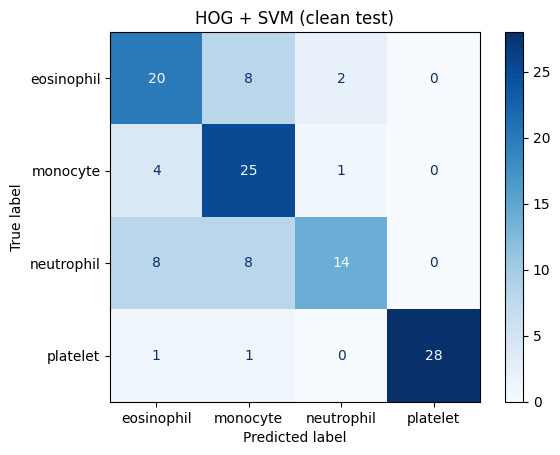

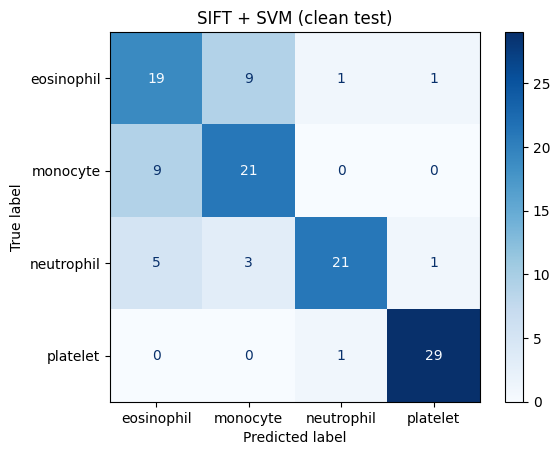

In [18]:
# Confusion matrices on clean test set (helps answer Q5 part 2)
for model, F, title in [(hog_model, hog_features(X_test), 'HOG + SVM'),
                        (sift_model, sift_features(X_test), 'SIFT + SVM')]:
    cm = confusion_matrix(y_test, model.predict(F), labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=[NAMES[c] for c in CLASSES]).plot(cmap='Blues')
    plt.title(title + ' (clean test)')
    plt.show()